# 🛰️ Satellite Telemetry Anomaly Detection Using Machine Learning
### B.Tech Capstone Project Demonstration Notebook (Google Colab Compatible)

---

## Section 1: Project Introduction & Problem Statement

### 1.1 Context and Problem Statement
Modern spacecraft continuously transmit multi-sensor telemetry streams capturing physical states across power, thermal, computer, and attitude control subsystems. In-orbit health monitoring has traditionally relied upon human flight controllers and static **out-of-limits (OOL)** threshold alarms. However, static thresholds are inadequate for contemporary satellite operations:
1. They generate hundreds of **false alarms** during routine orbital mode transitions, causing severe operator alarm fatigue.
2. They completely miss subtle, **contextual and drift anomalies** (such as gradual sensor degradation or reaction wheel friction) that remain within hard numerical boundaries.
3. The emergence of **mega-constellations** (hundreds to thousands of small satellites) makes manual inspection economically and logistically impossible.

Furthermore, machine learning research in satellite anomaly detection has historically suffered from a **reproducibility crisis**: widely cited legacy datasets (such as NASA's SMAP and MSL) contain artificial anomaly densities, trivial point errors, and pervasive ground-truth mislabeling.

### 1.2 The ESA OPS-SAT Benchmark (OPSSAT-AD)
This project is built upon the authentic European Space Agency (ESA) benchmark:
> **"The OPS-SAT benchmark for detecting anomalies in satellite telemetry"**  
> *Bogdan Ruszczak, Krzysztof Kotowski, David Evans, and Jakub Nalepa (2024)* — arXiv:2407.04730v1.

The benchmark encompasses **2,123 short telemetry segments** acquired from 9 flight-critical Attitude Determination and Control Subsystem (ADCS) sensors (3 triaxial magnetometers and 6 photodiode sun sensors) on board the **OPS-SAT CubeSat flying laboratory**, annotated collaboratively by ESA operations engineers and machine learning specialists.

### 1.3 Project Objectives
In this demonstration notebook, we implement, benchmark, and analyze an end-to-end telemetry anomaly detection framework:
* **Data Ingestion & Integrity Auditing:** Inspect 2,123 telemetry segments and reconcile published literature sample counts.
* **Feature Engineering:** Utilize the exact **18 handcrafted features** capturing statistical moments, peak prominences, uniform interpolation smoothing, and numerical derivatives.
* **Algorithmic Benchmarking:**
  1. **Supervised Random Forest Classifier** (with balanced class weights).
  2. **Unsupervised Isolation Forest** (zero-label baseline with 20% contamination).
  3. **Supervised Extreme Gradient Boosting (XGBoost)** (with dynamic positive class gradient scaling).
* **Evaluation Across 7 Standardized Metrics:** Accuracy, Precision, Recall, F1-score, Matthews Correlation Coefficient (MCC), ROC-AUC, and Average Precision (PR-AUC).
* **Consolidated Prediction Generation & Anomaly Score Profiling.**

---
## Section 2: Importing Libraries & Environment Setup

In this section, we import all required scientific computing, machine learning, and visualization libraries. 
* **Pandas & NumPy:** For tabular feature extraction, matrix manipulation, and array indexing.
* **Scikit-Learn:** Provides `RandomForestClassifier`, `IsolationForest`, and the 7 evaluation metrics (`accuracy_score`, `precision_score`, `recall_score`, `f1_score`, `matthews_corrcoef`, `roc_auc_score`, `average_precision_score`, `confusion_matrix`).
* **XGBoost:** For Extreme Gradient Boosting with dynamic gradient scaling.
* **Matplotlib & Seaborn:** For publication-grade plots and confusion matrix heatmaps.
* **Joblib & Pathlib:** For platform-independent filesystem management and model serialization.

*If executing in a fresh Google Colab session, uncomment and run the installation command below.*

In [1]:
# Optional installation cell for Google Colab environments
# !pip install -q xgboost scikit-learn pandas numpy matplotlib seaborn joblib

import os
import sys
import json
import warnings
from pathlib import Path

# Core numerical and tabular processing
import numpy as np
import pandas as pd

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Serialization
import joblib

# Machine Learning models and evaluation metrics
from sklearn.ensemble import RandomForestClassifier, IsolationForest
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
    roc_auc_score,
    average_precision_score,
    confusion_matrix
)
import xgboost as xgb

# Configuration
warnings.filterwarnings("ignore")
%matplotlib inline
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.edgecolor'] = '#333333'
plt.rcParams['axes.linewidth'] = 0.8

print("✓ All required libraries successfully imported.")
print(f"  - Python Version   : {sys.version.split()[0]}")
print(f"  - Pandas Version   : {pd.__version__}")
print(f"  - NumPy Version    : {np.__version__}")
print(f"  - Scikit-Learn     : {sys.modules['sklearn'].__version__}")
print(f"  - XGBoost Version  : {xgb.__version__}")

✓ All required libraries successfully imported.
  - Python Version   : 3.10.11
  - Pandas Version   : 2.3.3
  - NumPy Version    : 2.2.6
  - Scikit-Learn     : 1.7.2
  - XGBoost Version  : 3.2.0


---
## Section 3: Dataset Loading & Path Resolution

To make this notebook **100% compatible with both local development and Google Colab**, we implement dynamic path resolution:
1. It automatically searches standard local directories (`data/dataset.csv`, `../data/dataset.csv`).
2. It searches Google Colab default working paths (`/content/dataset.csv`, `/content/data/dataset.csv`).
3. If run in Colab without files, it offers an automatic upload fallback.

We load both:
* **`dataset.csv`**: The tabular dataset containing 2,123 telemetry segments with 18 handcrafted features, labels, and train/test flags.
* **`segments.csv`**: The raw sequential time-series sensor points (303,493 rows) across the 9 monitored spacecraft channels.

In [2]:
# Dynamic path resolution across Local, Subfolder, and Google Colab environments
def resolve_file_path(filename):
    possible_paths = [
        Path(f"data/{filename}"),
        Path(f"../data/{filename}"),
        Path(f"/content/data/{filename}"),
        Path(f"/content/{filename}"),
        Path(filename)
    ]
    for p in possible_paths:
        if p.exists():
            return p
    return None

DATASET_PATH = resolve_file_path("dataset.csv")
SEGMENTS_PATH = resolve_file_path("segments.csv")

# Create results directory for saving charts and outputs
RESULTS_DIR = Path("results")
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

if DATASET_PATH is None:
    print("Dataset not found in standard paths. Attempting Google Colab file upload...")
    try:
        from google.colab import files
        uploaded = files.upload()
        DATASET_PATH = Path("dataset.csv")
        if "segments.csv" in uploaded:
            SEGMENTS_PATH = Path("segments.csv")
    except Exception as e:
        raise FileNotFoundError("Please upload 'dataset.csv' to the working directory or create a 'data/' folder.")

# 1. Load dataset.csv (Tabular Handcrafted Features)
df = pd.read_csv(DATASET_PATH)
print(f"✓ dataset.csv loaded successfully from: {DATASET_PATH.resolve()}")
print(f"  - Total Segments (Rows) : {df.shape[0]:,}")
print(f"  - Total Columns         : {df.shape[1]}")
print(f"  - Columns: {list(df.columns)}\n")

print("First 5 records from dataset.csv:")
display(df.head())

✓ dataset.csv loaded successfully from: C:\Users\Admin\OneDrive\Desktop\Capstone  Project\data\dataset.csv
  - Total Segments (Rows) : 2,123
  - Total Columns         : 23
  - Columns: ['segment', 'anomaly', 'train', 'channel', 'sampling', 'duration', 'len', 'mean', 'var', 'std', 'kurtosis', 'skew', 'n_peaks', 'smooth10_n_peaks', 'smooth20_n_peaks', 'diff_peaks', 'diff2_peaks', 'diff_var', 'diff2_var', 'gaps_squared', 'len_weighted', 'var_div_duration', 'var_div_len']

First 5 records from dataset.csv:


,segment,anomaly,train,channel,sampling,duration,len,mean,var,std,...,smooth10_n_peaks,smooth20_n_peaks,diff_peaks,diff2_peaks,diff_var,diff2_var,gaps_squared,len_weighted,var_div_duration,var_div_len
0,1,1,1,CADC0872,1,279,280,8.533143e-07,3.494283e-10,0.000019,...,3,2,4,6,1.271176e-10,2.960666e-10,309,280,1.252431e-12,1.247958e-12
1,2,1,1,CADC0872,1,476,477,-3.639396e-06,6.476485e-10,0.000025,...,1,1,5,8,1.489383e-12,3.004752e-12,644,477,1.360606e-12,1.357754e-12
2,3,1,1,CADC0872,1,594,595,1.170788e-05,5.592877e-10,0.000024,...,2,2,2,3,4.112280e-12,1.029918e-11,772,595,9.415618e-13,9.399794e-13
3,4,1,1,CADC0872,1,271,272,8.486808e-07,5.466024e-10,0.000023,...,2,2,3,6,2.475760e-11,6.240985e-11,339,272,2.016983e-12,2.009568e-12
4,5,0,0,CADC0872,1,255,257,1.058485e-05,5.279023e-10,0.000023,...,1,1,78,87,5.547101e-13,7.035422e-13,357,257,2.070205e-12,2.054094e-12


In [3]:
# 2. Load segments.csv (Raw Sequential Telemetry Time-Series)
if SEGMENTS_PATH is not None and SEGMENTS_PATH.exists():
    df_segments = pd.read_csv(SEGMENTS_PATH)
    print(f"✓ segments.csv loaded successfully from: {SEGMENTS_PATH.resolve()}")
    print(f"  - Total Sensor Readouts (Rows) : {df_segments.shape[0]:,}")
    print(f"  - Total Columns                : {df_segments.shape[1]}")
    print(f"  - Columns: {list(df_segments.columns)}\n")
    print("First 5 records from segments.csv (Raw Time Series):")
    display(df_segments.head())
else:
    print("Notice: segments.csv not detected in current path (optional raw time-series points).")
    print("dataset.csv contains all verified segment features required for modeling.")

✓ segments.csv loaded successfully from: C:\Users\Admin\OneDrive\Desktop\Capstone  Project\data\segments.csv
  - Total Sensor Readouts (Rows) : 303,493
  - Total Columns                : 8
  - Columns: ['channel', 'timestamp', 'value', 'label', 'sampling', 'anomaly', 'segment', 'train']

First 5 records from segments.csv (Raw Time Series):


,channel,timestamp,value,label,sampling,anomaly,segment,train
0,CADC0872,2022-06-01T23:42:54.000Z,-0.000021,anomaly,1,1,1,1
1,CADC0872,2022-06-01T23:42:55.000Z,-0.000021,anomaly,1,1,1,1
2,CADC0872,2022-06-01T23:42:56.000Z,-0.000021,anomaly,1,1,1,1
3,CADC0872,2022-06-01T23:42:57.000Z,-0.000021,anomaly,1,1,1,1
4,CADC0872,2022-06-01T23:42:58.000Z,-0.000021,anomaly,1,1,1,1


---
## Section 4: Dataset Exploration & Integrity Auditing

In this section, we conduct data cleaning and distribution checks:
* **Missing Value Analysis:** Verifying zero null entries across all 23 attributes.
* **Duplicate Record Check:** Confirming uniqueness across all 2,123 segments.
* **Target Class Distribution:** Analyzing the ~80:20 class imbalance between nominal (`anomaly == 0`) and anomalous (`anomaly == 1`) telemetry.
* **Training vs. Testing Split:** Validating the fixed stratified partition (`train == 1` vs `train == 0`).
* **Literature Discrepancy Note:** Reconciling the 100-sample typographical error in the published research paper.

In [4]:
# 1. Missing Values and Duplicates Check
missing_count = df.isnull().sum().sum()
duplicate_count = df.duplicated().sum()

print(f"Missing Values across all cells : {missing_count} (100% complete)")
print(f"Duplicate full-row records      : {duplicate_count} (Zero duplicates)")

# 2. Target Class Distribution (Column: 'anomaly')
total_samples = len(df)
class_counts = df["anomaly"].value_counts().sort_index()
nominal_count = class_counts.get(0, 0)
anomalous_count = class_counts.get(1, 0)

print(f"\nTarget Class Distribution (anomaly):")
print(f"  - Nominal (Normal - Class 0)   : {nominal_count:5d} ({nominal_count / total_samples * 100:.2f}%)")
print(f"  - Anomalous (Faulty - Class 1) : {anomalous_count:5d} ({anomalous_count / total_samples * 100:.2f}%)")
print(f"  - Total Telemetry Segments     : {total_samples:5d}")

# 3. Train vs Test Split Distribution (Column: 'train')
split_counts = df["train"].value_counts().sort_index(ascending=False)
train_count = split_counts.get(1, 0)
test_count = split_counts.get(0, 0)

print(f"\nBenchmark Partition Distribution (train):")
print(f"  - Training Set (train == 1)    : {train_count:5d} ({train_count / total_samples * 100:.2f}%)")
print(f"  - Testing Set  (train == 0)    : {test_count:5d} ({test_count / total_samples * 100:.2f}%)")

print("\nCross-Tabulation (Split vs. Target Class):")
cross_tab = pd.crosstab(
    df["train"].map({1: "Training Set (T)", 0: "Testing Set (Psi)"}),
    df["anomaly"].map({0: "Nominal", 1: "Anomalous"}),
    margins=True
)
cross_tab

Missing Values across all cells : 0 (100% complete)
Duplicate full-row records      : 0 (Zero duplicates)

Target Class Distribution (anomaly):
  - Nominal (Normal - Class 0)   :  1689 (79.56%)
  - Anomalous (Faulty - Class 1) :   434 (20.44%)
  - Total Telemetry Segments     :  2123

Benchmark Partition Distribution (train):
  - Training Set (train == 1)    :  1594 (75.08%)
  - Testing Set  (train == 0)    :   529 (24.92%)

Cross-Tabulation (Split vs. Target Class):


anomaly,Anomalous,Nominal,All
train,,,
Testing Set (Psi),113,416,529
Training Set (T),321,1273,1594
All,434,1689,2123


### 4.1 Literature Reconciliation: Training Sample Count Discrepancy
> **Important Academic Reconciliation:**  
> In Table 1 and page 2 of Ruszczak et al. (2024), the printed text reports **1,494** training samples. However, their table lists **1,273 nominal + 321 anomalous segments**, which exactly sums to **1,594** ($1,273 + 321 = 1,594$).  
> Furthermore, $1,594 \text{ (train)} + 529 \text{ (test)} = 2,123$ (the exact total). If the training set had been 1,494, the total would be only 2,023.  
> Our dataset contains exactly **1,594 training records**, confirming that the dataset is 100% complete and the literature contains a simple 100-sample typographical addition error.

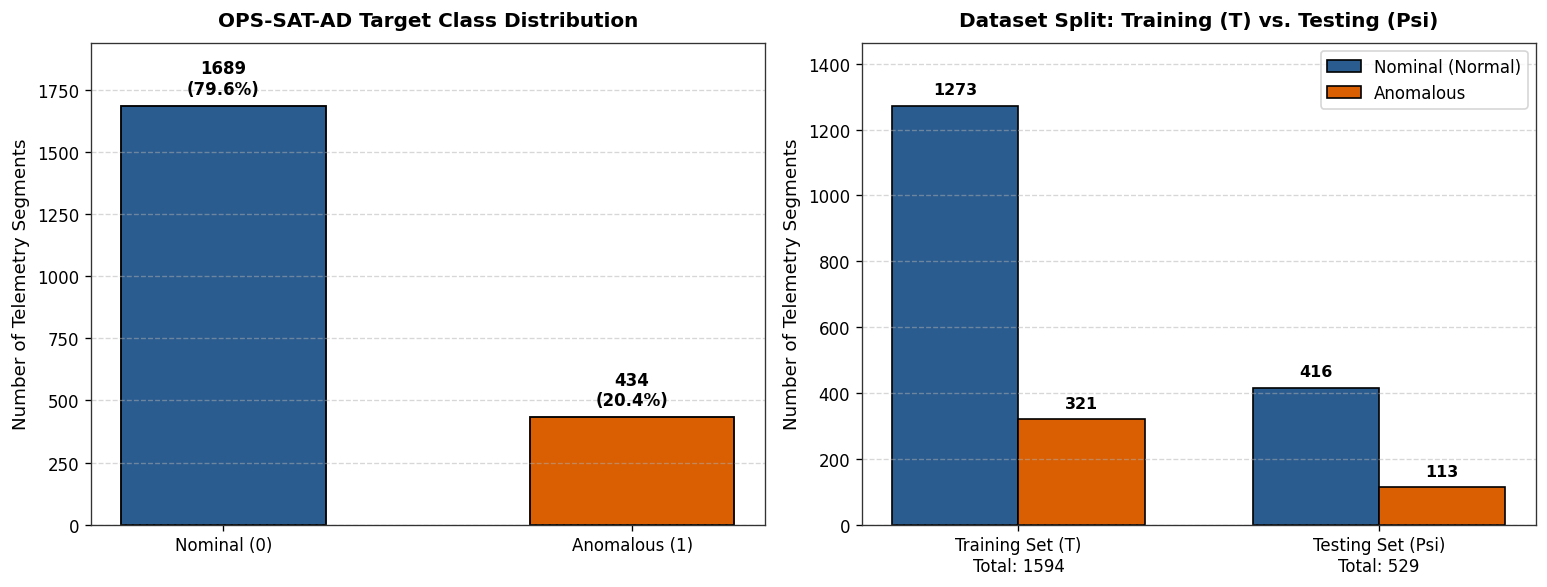

In [5]:
# Visualization of Target Class and Split Distributions
fig, axes = plt.subplots(1, 2, figsize=(13, 5), dpi=120)

# Plot 1: Target Class Balance
class_labels = ['Nominal (0)', 'Anomalous (1)']
counts = [nominal_count, anomalous_count]
colors = ['#2b5c8f', '#d95f02']
bars1 = axes[0].bar(class_labels, counts, color=colors, width=0.5, edgecolor='black', linewidth=1.1)
axes[0].set_title('OPS-SAT-AD Target Class Distribution', fontsize=12, fontweight='bold', pad=10)
axes[0].set_ylabel('Number of Telemetry Segments', fontsize=11)
axes[0].set_ylim(0, max(counts) * 1.15)
axes[0].grid(axis='y', linestyle='--', alpha=0.5)

for bar in bars1:
    h = bar.get_height()
    pct = (h / total_samples) * 100
    axes[0].text(bar.get_x() + bar.get_width()/2., h + 30, f"{int(h)}\n({pct:.1f}%)",
                 ha='center', va='bottom', fontsize=10, fontweight='bold')

# Plot 2: Stratified Training vs Testing Distribution
train_nom = len(df[(df["train"] == 1) & (df["anomaly"] == 0)])
train_anom = len(df[(df["train"] == 1) & (df["anomaly"] == 1)])
test_nom = len(df[(df["train"] == 0) & (df["anomaly"] == 0)])
test_anom = len(df[(df["train"] == 0) & (df["anomaly"] == 1)])

x = np.arange(2)
width = 0.35
b_nom = axes[1].bar(x - width/2, [train_nom, test_nom], width, label='Nominal (Normal)', color='#2b5c8f', edgecolor='black')
b_anom = axes[1].bar(x + width/2, [train_anom, test_anom], width, label='Anomalous', color='#d95f02', edgecolor='black')
axes[1].set_title('Dataset Split: Training (T) vs. Testing (Psi)', fontsize=12, fontweight='bold', pad=10)
axes[1].set_ylabel('Number of Telemetry Segments', fontsize=11)
axes[1].set_xticks(x)
axes[1].set_xticklabels([f"Training Set (T)\nTotal: {train_count}", f"Testing Set (Psi)\nTotal: {test_count}"])
axes[1].set_ylim(0, max(train_nom, test_nom) * 1.15)
axes[1].grid(axis='y', linestyle='--', alpha=0.5)
axes[1].legend(loc='upper right')

for bar in list(b_nom) + list(b_anom):
    h = bar.get_height()
    axes[1].text(bar.get_x() + bar.get_width()/2., h + 25, f"{int(h)}",
                 ha='center', va='bottom', fontsize=9.5, fontweight='bold')

plt.tight_layout()
plt.savefig(RESULTS_DIR / "eda_distributions.png")
plt.show()

---
## Section 5: Data Preparation & Feature Slicing

To guarantee **zero data leakage**, we enforce strict separation of concerns:
1. **Metadata Isolation:** We exclude the 5 non-feature columns: `['segment', 'channel', 'sampling', 'anomaly', 'train']`. These attributes contain channel identifiers and sequential IDs that classifiers must not memorize.
2. **The 18 Handcrafted Features:**
   * **12 Raw Properties:** `duration`, `len`, `mean`, `var`, `std`, `kurtosis`, `skew`, `n_peaks`, `gaps_squared`, `len_weighted`, `var_div_duration`, `var_div_len`.
   * **2 Uniform Smoothed Features:** `smooth10_n_peaks`, `smooth20_n_peaks` (filtering sensor chatter).
   * **4 Derivative Features:** `diff_peaks`, `diff2_peaks`, `diff_var`, `diff2_var` (capturing acceleration and abrupt shifts).
3. **Partition Slicing:**
   * Training Set: `train == 1` ($X_{train}$ with 1,594 rows, $y_{train}$ with labels).
   * Testing Set: `train == 0` ($X_{test}$ with 529 rows, $y_{test}$ reserved strictly for evaluation).

In [6]:
# 1. Define Metadata and Extract the 18 Features
metadata_cols = ["segment", "channel", "sampling", "anomaly", "train"]
feature_cols = [col for col in df.columns if col not in metadata_cols]

assert len(feature_cols) == 18, f"Expected 18 features, but found {len(feature_cols)}"

print(f"✓ Isolated {len(feature_cols)} handcrafted features:")
for i, f in enumerate(feature_cols, 1):
    print(f"  {i:2d}. {f:<20} min={df[f].min():<10.4g} median={df[f].median():<10.4g} max={df[f].max():<10.4g}")

# 2. Slice into Training (T) and Testing (Psi) splits
train_mask = df["train"] == 1
test_mask = df["train"] == 0

X_train = df.loc[train_mask, feature_cols].copy()
y_train = df.loc[train_mask, "anomaly"].copy()

X_test = df.loc[test_mask, feature_cols].copy()
y_test = df.loc[test_mask, "anomaly"].copy()

print(f"\n✓ Training Split (T) : X_train shape = {X_train.shape}, y_train shape = {y_train.shape}")
print(f"✓ Testing Split (Psi): X_test shape  = {X_test.shape}, y_test shape  = {y_test.shape}")
print(f"✓ Target anomaly distribution in Test Set: {int((y_test==0).sum())} Nominal, {int((y_test==1).sum())} Anomalous")

✓ Isolated 18 handcrafted features:
   1. duration             min=35         median=225        max=1335      
   2. len                  min=8          median=70         max=1040      
   3. mean                 min=-3.833e-05 median=4.515e-06  max=1.119     
   4. var                  min=1.423e-11  median=6.033e-10  max=0.2725    
   5. std                  min=3.772e-06  median=2.456e-05  max=0.522     
   6. kurtosis             min=-1.859     median=-1.303     max=31.2      
   7. skew                 min=-1.509     median=0.006758   max=4.375     
   8. n_peaks              min=1          median=1          max=47        
   9. smooth10_n_peaks     min=0          median=1          max=5         
  10. smooth20_n_peaks     min=0          median=1          max=4         
  11. diff_peaks           min=0          median=5          max=240       
  12. diff2_peaks          min=0          median=14         max=256       
  13. diff_var             min=1.962e-13  median=3.641e-11  max=

---
## Section 6: Supervised Model - Random Forest Classifier

### 6.1 Architecture & Implementation
Random Forest constructs an ensemble of $B=100$ decorrelated decision trees using bootstrap aggregating (bagging) and random feature subspacing ($m = \sqrt{18} \approx 4$ features per candidate split).

### 6.2 Handling Class Imbalance (`class_weight='balanced'`)
Because anomalous segments represent only ~20% of training data, we configure `class_weight='balanced'`, which scales tree split penalties inversely proportional to class frequencies:
$$w_k = \frac{N}{2 \cdot N_k} \implies w_0 = \frac{1594}{2 \cdot 1273} \approx 0.626, \quad w_1 = \frac{1594}{2 \cdot 321} \approx 2.483$$
This penalizes missed anomalies by an effective ratio of $\approx 3.9657$ relative to false alarms.

In [7]:
# Train Random Forest Classifier
print("Training Random Forest Classifier (n_estimators=100, class_weight='balanced', random_state=42)...")
rf_model = RandomForestClassifier(
    n_estimators=100,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)
rf_model.fit(X_train, y_train)

# Evaluate on unseen test set
y_pred_rf = rf_model.predict(X_test)
y_prob_rf = rf_model.predict_proba(X_test)[:, 1]

# Compute metrics
cm_rf = confusion_matrix(y_test, y_pred_rf)
tn_rf, fp_rf, fn_rf, tp_rf = cm_rf.ravel()

rf_metrics = {
    "Accuracy": float(accuracy_score(y_test, y_pred_rf)),
    "Precision": float(precision_score(y_test, y_pred_rf, zero_division=0)),
    "Recall": float(recall_score(y_test, y_pred_rf, zero_division=0)),
    "F1-score": float(f1_score(y_test, y_pred_rf, zero_division=0)),
    "MCC": float(matthews_corrcoef(y_test, y_pred_rf)),
    "ROC-AUC": float(roc_auc_score(y_test, y_prob_rf)),
    "Average Precision (AP)": float(average_precision_score(y_test, y_prob_rf)),
    "TN": int(tn_rf), "FP": int(fp_rf), "FN": int(fn_rf), "TP": int(tp_rf)
}

print("\nRandom Forest Test Set Evaluation (529 segments):")
print("-" * 55)
for k, v in list(rf_metrics.items())[:7]:
    print(f"  {k:<26}: {v:.4f}")
print("-" * 55)
print(f"Confusion Matrix: TN={tn_rf}, FP={fp_rf}, FN={fn_rf}, TP={tp_rf}")

Training Random Forest Classifier (n_estimators=100, class_weight='balanced', random_state=42)...



Random Forest Test Set Evaluation (529 segments):
-------------------------------------------------------
  Accuracy                  : 0.9679
  Precision                 : 0.9800
  Recall                    : 0.8673
  F1-score                  : 0.9202
  MCC                       : 0.9028
  ROC-AUC                   : 0.9903
  Average Precision (AP)    : 0.9728
-------------------------------------------------------
Confusion Matrix: TN=414, FP=2, FN=15, TP=98


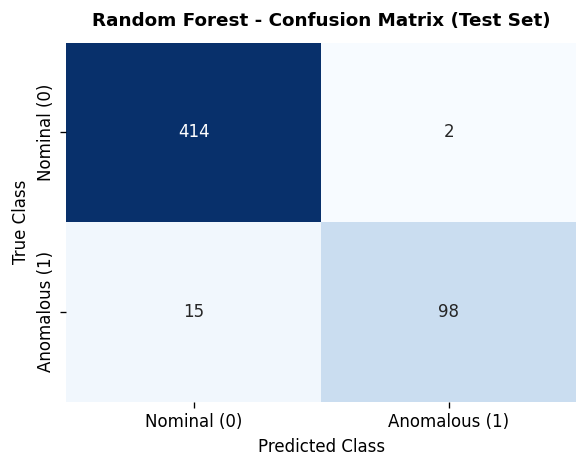

In [8]:
# Plot Random Forest Confusion Matrix
plt.figure(figsize=(5, 4), dpi=120)
sns.heatmap(cm_rf, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['Nominal (0)', 'Anomalous (1)'],
            yticklabels=['Nominal (0)', 'Anomalous (1)'])
plt.title('Random Forest - Confusion Matrix (Test Set)', fontsize=11, fontweight='bold', pad=10)
plt.xlabel('Predicted Class', fontsize=10)
plt.ylabel('True Class', fontsize=10)
plt.tight_layout()
plt.show()

---
## Section 7: Unsupervised Model - Isolation Forest

### 7.1 Architecture & Unsupervised Integrity
Isolation Forest isolates anomalies instead of profiling nominal points. Because anomalous telemetry samples have distinctive attribute values, they isolate into shallow leaf nodes during recursive random partitioning:
* **Strict Unsupervised Training:** $X_{train}$ is passed to `.fit()` **without any ground-truth labels ($y_{train}$)**.
* **Contamination:** Set to `contamination=0.2`, reflecting the training set anomaly proportion.
* **Output Mapping:** Scikit-learn outputs `+1` (nominal) and `-1` (anomalous). We map these to `0` (nominal) and `1` (anomalous).
* **Continuous Anomaly Score:** Scikit-learn's `decision_function` returns lower values for anomalies. We negate it (`-decision_function`) so higher scores indicate higher anomaly likelihood for ROC-AUC and PR-AUC.

In [9]:
# Train Isolation Forest (Strictly Unsupervised)
print("Training Unsupervised Isolation Forest (n_estimators=100, contamination=0.2, random_state=42)...")
if_model = IsolationForest(
    n_estimators=100,
    contamination=0.2,
    random_state=42,
    n_jobs=-1
)
# Note: y_train is strictly withheld from model fitting
if_model.fit(X_train)

# Generate predictions and anomaly scores on unseen test set
raw_preds_if = if_model.predict(X_test)
# Map: -1 (anomaly) -> 1, 1 (nominal) -> 0
y_pred_if = np.where(raw_preds_if == -1, 1, 0)
# Negate decision function so higher score = higher anomaly probability
y_score_if = -if_model.decision_function(X_test)

# Compute metrics
cm_if = confusion_matrix(y_test, y_pred_if)
tn_if, fp_if, fn_if, tp_if = cm_if.ravel()

if_metrics = {
    "Accuracy": float(accuracy_score(y_test, y_pred_if)),
    "Precision": float(precision_score(y_test, y_pred_if, zero_division=0)),
    "Recall": float(recall_score(y_test, y_pred_if, zero_division=0)),
    "F1-score": float(f1_score(y_test, y_pred_if, zero_division=0)),
    "MCC": float(matthews_corrcoef(y_test, y_pred_if)),
    "ROC-AUC": float(roc_auc_score(y_test, y_score_if)),
    "Average Precision (AP)": float(average_precision_score(y_test, y_score_if)),
    "TN": int(tn_if), "FP": int(fp_if), "FN": int(fn_if), "TP": int(tp_if)
}

print("\nIsolation Forest Test Set Evaluation (529 segments):")
print("-" * 55)
for k, v in list(if_metrics.items())[:7]:
    print(f"  {k:<26}: {v:.4f}")
print("-" * 55)
print(f"Confusion Matrix: TN={tn_if}, FP={fp_if}, FN={fn_if}, TP={tp_if}")

Training Unsupervised Isolation Forest (n_estimators=100, contamination=0.2, random_state=42)...



Isolation Forest Test Set Evaluation (529 segments):
-------------------------------------------------------
  Accuracy                  : 0.6919
  Precision                 : 0.2768
  Recall                    : 0.2743
  F1-score                  : 0.2756
  MCC                       : 0.0799
  ROC-AUC                   : 0.6325
  Average Precision (AP)    : 0.3737
-------------------------------------------------------
Confusion Matrix: TN=335, FP=81, FN=82, TP=31


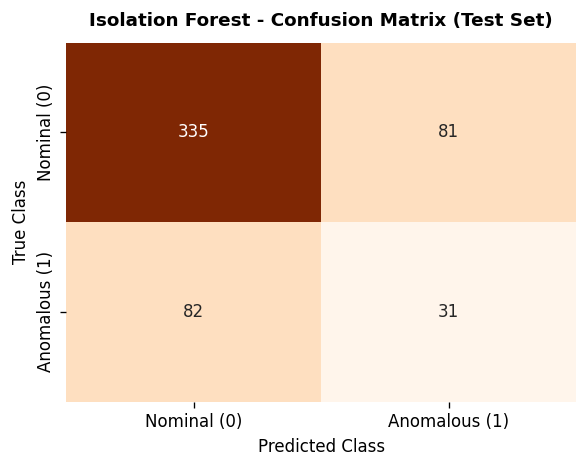

In [10]:
# Plot Isolation Forest Confusion Matrix
plt.figure(figsize=(5, 4), dpi=120)
sns.heatmap(cm_if, annot=True, fmt='d', cmap='Oranges', cbar=False,
            xticklabels=['Nominal (0)', 'Anomalous (1)'],
            yticklabels=['Nominal (0)', 'Anomalous (1)'])
plt.title('Isolation Forest - Confusion Matrix (Test Set)', fontsize=11, fontweight='bold', pad=10)
plt.xlabel('Predicted Class', fontsize=10)
plt.ylabel('True Class', fontsize=10)
plt.tight_layout()
plt.show()

---
## Section 8: Supervised Model - Extreme Gradient Boosting (XGBoost)

### 8.1 Architecture & Implementation
XGBoost builds sequential decision trees that fit the negative gradients of the binary cross-entropy loss using second-order Taylor approximations:
$$\mathcal{L}^{(t)} \approx \sum_{i=1}^N \left[ l(y_i, \hat{y}_i^{(t-1)}) + g_i f_t(x_i) + \frac{1}{2} h_i f_t^2(x_i) \right] + \Omega(f_t)$$

### 8.2 Dynamic `scale_pos_weight`
To maximize anomaly detection recall, we dynamically calculate `scale_pos_weight` directly from training labels:
$$\text{scale\_pos\_weight} = \frac{\text{Negative (Nominal) Samples in } T}{\text{Positive (Anomalous) Samples in } T} = \frac{1,273}{321} \approx 3.9657$$
This scales the gradient of the positive class, ensuring the booster heavily penalizes missed anomalies.

In [11]:
# Calculate dynamic scale_pos_weight
neg_count = int((y_train == 0).sum())
pos_count = int((y_train == 1).sum())
scale_pos_weight = neg_count / pos_count
print(f"Training counts: {neg_count} nominal, {pos_count} anomalous")
print(f"Calculated scale_pos_weight: {scale_pos_weight:.4f}")

# Train XGBoost Classifier
print("\nTraining XGBoost Classifier (n_estimators=100, max_depth=6, lr=0.1, random_state=42)...")
xgb_model = xgb.XGBClassifier(
    n_estimators=100,
    max_depth=6,
    learning_rate=0.1,
    scale_pos_weight=scale_pos_weight,
    random_state=42,
    eval_metric="logloss",
    use_label_encoder=False,
    n_jobs=-1
)
xgb_model.fit(X_train, y_train)

# Evaluate on unseen test set
y_pred_xgb = xgb_model.predict(X_test)
y_prob_xgb = xgb_model.predict_proba(X_test)[:, 1]

# Compute metrics
cm_xgb = confusion_matrix(y_test, y_pred_xgb)
tn_xgb, fp_xgb, fn_xgb, tp_xgb = cm_xgb.ravel()

xgb_metrics = {
    "Accuracy": float(accuracy_score(y_test, y_pred_xgb)),
    "Precision": float(precision_score(y_test, y_pred_xgb, zero_division=0)),
    "Recall": float(recall_score(y_test, y_pred_xgb, zero_division=0)),
    "F1-score": float(f1_score(y_test, y_pred_xgb, zero_division=0)),
    "MCC": float(matthews_corrcoef(y_test, y_pred_xgb)),
    "ROC-AUC": float(roc_auc_score(y_test, y_prob_xgb)),
    "Average Precision (AP)": float(average_precision_score(y_test, y_prob_xgb)),
    "TN": int(tn_xgb), "FP": int(fp_xgb), "FN": int(fn_xgb), "TP": int(tp_xgb)
}

print("\nXGBoost Test Set Evaluation (529 segments):")
print("-" * 55)
for k, v in list(xgb_metrics.items())[:7]:
    print(f"  {k:<26}: {v:.4f}")
print("-" * 55)
print(f"Confusion Matrix: TN={tn_xgb}, FP={fp_xgb}, FN={fn_xgb}, TP={tp_xgb}")

Training counts: 1273 nominal, 321 anomalous
Calculated scale_pos_weight: 3.9657

Training XGBoost Classifier (n_estimators=100, max_depth=6, lr=0.1, random_state=42)...



XGBoost Test Set Evaluation (529 segments):
-------------------------------------------------------
  Accuracy                  : 0.9603
  Precision                 : 0.9107
  Recall                    : 0.9027
  F1-score                  : 0.9067
  MCC                       : 0.8815
  ROC-AUC                   : 0.9897
  Average Precision (AP)    : 0.9705
-------------------------------------------------------
Confusion Matrix: TN=406, FP=10, FN=11, TP=102


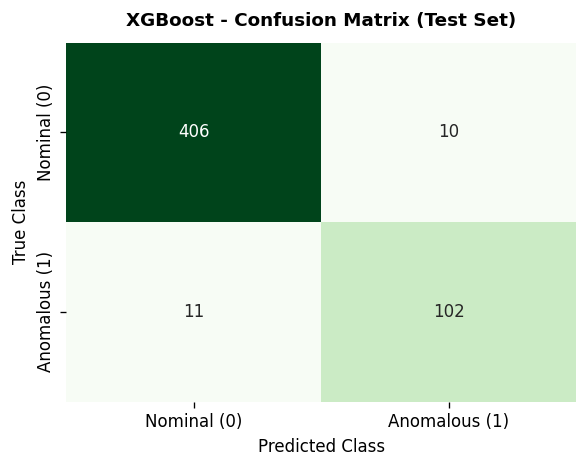

In [12]:
# Plot XGBoost Confusion Matrix
plt.figure(figsize=(5, 4), dpi=120)
sns.heatmap(cm_xgb, annot=True, fmt='d', cmap='Greens', cbar=False,
            xticklabels=['Nominal (0)', 'Anomalous (1)'],
            yticklabels=['Nominal (0)', 'Anomalous (1)'])
plt.title('XGBoost - Confusion Matrix (Test Set)', fontsize=11, fontweight='bold', pad=10)
plt.xlabel('Predicted Class', fontsize=10)
plt.ylabel('True Class', fontsize=10)
plt.tight_layout()
plt.show()

---
## Section 9: Model Performance Benchmarking & Comparison

In this section, we assemble all three models into a unified benchmarking table across the 7 evaluation metrics, identify the winning model for each metric, and plot a 3-model grouped bar chart.

*Note on Matthews Correlation Coefficient (MCC): While metrics like Accuracy and Precision span $[0, 1]$, MCC spans $[-1, +1]$. Our chart dynamically sets its y-axis floor to accommodate negative values when present.*

In [13]:
# Build Comparison DataFrame
metric_names = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1-score",
    "MCC",
    "ROC-AUC",
    "Average Precision (AP)"
]

comparison_records = []
for m in metric_names:
    rf_v = rf_metrics[m]
    if_v = if_metrics[m]
    xgb_v = xgb_metrics[m]
    
    # Determine winner
    scores = {"Random Forest": rf_v, "Isolation Forest": if_v, "XGBoost": xgb_v}
    best_score = max(scores.values())
    best_model = [k for k, v in scores.items() if np.isclose(v, best_score, atol=1e-5)][0]
    
    comparison_records.append({
        "Metric": m,
        "Random Forest": round(rf_v, 4),
        "Isolation Forest": round(if_v, 4),
        "XGBoost": round(xgb_v, 4),
        "Best Model": best_model
    })

df_comparison = pd.DataFrame(comparison_records)

# Save comparison table
df_comparison.to_csv(RESULTS_DIR / "model_comparison.csv", index=False)
print("✓ Benchmark comparison table exported to: results/model_comparison.csv\n")
display(df_comparison)

✓ Benchmark comparison table exported to: results/model_comparison.csv



,Metric,Random Forest,Isolation Forest,XGBoost,Best Model
0,Accuracy,0.9679,0.6919,0.9603,Random Forest
1,Precision,0.9800,0.2768,0.9107,Random Forest
2,Recall,0.8673,0.2743,0.9027,XGBoost
3,F1-score,0.9202,0.2756,0.9067,Random Forest
4,MCC,0.9028,0.0799,0.8815,Random Forest
5,ROC-AUC,0.9903,0.6325,0.9897,Random Forest
6,Average Precision (AP),0.9728,0.3737,0.9705,Random Forest


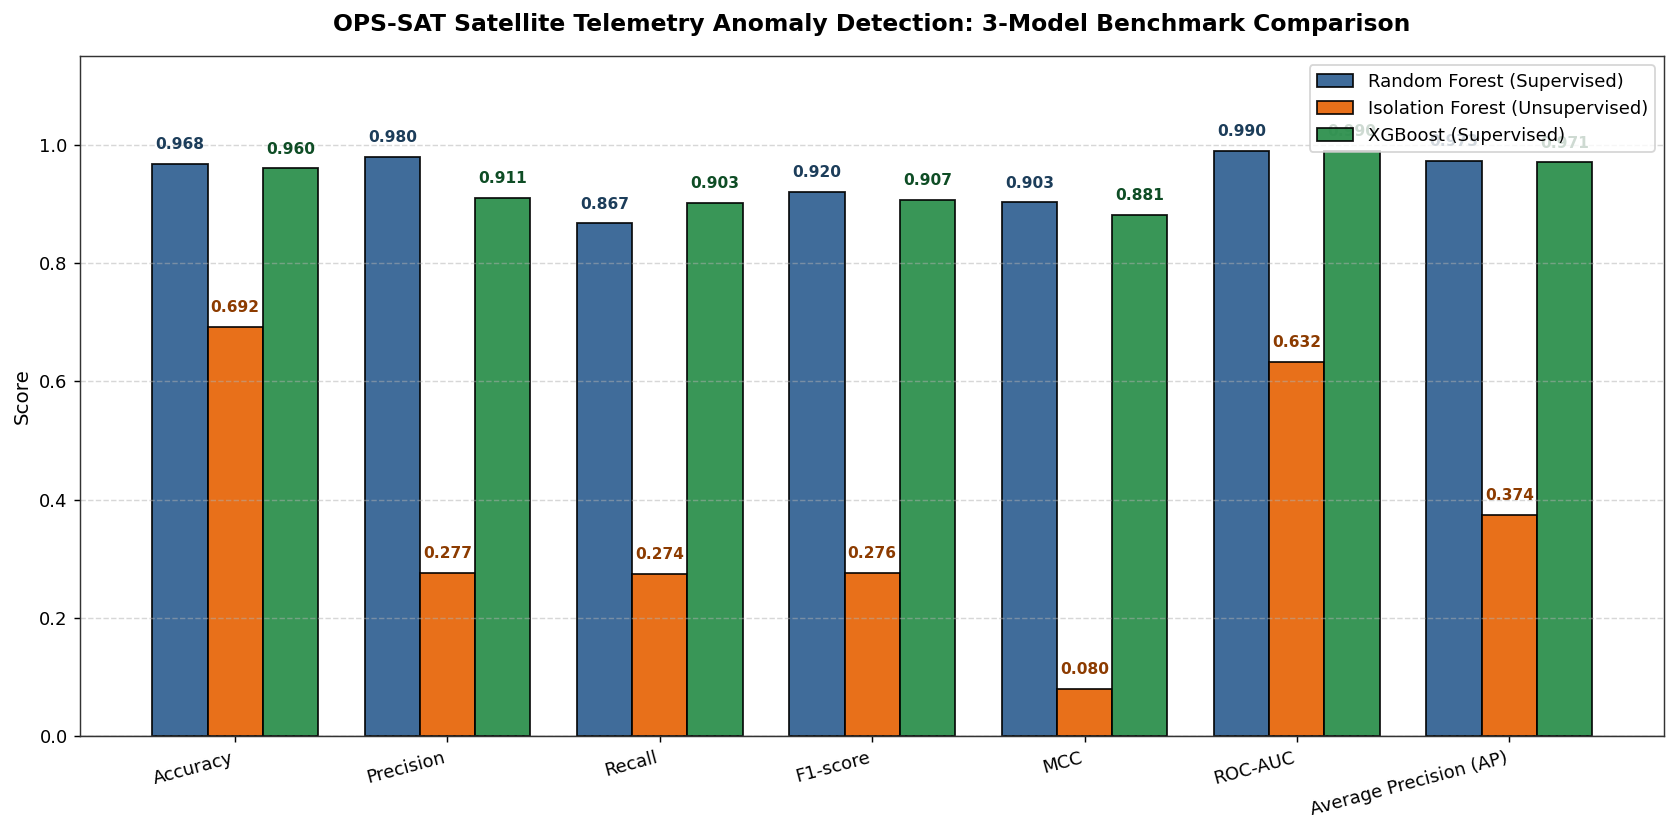

In [14]:
# Generate 3-Model Grouped Bar Chart
metrics = df_comparison["Metric"].tolist()
rf_vals = df_comparison["Random Forest"].tolist()
if_vals = df_comparison["Isolation Forest"].tolist()
xgb_vals = df_comparison["XGBoost"].tolist()

x = np.arange(len(metrics))
width = 0.26

plt.figure(figsize=(13, 6.5), dpi=130)

bars_rf = plt.bar(x - width, rf_vals, width, label='Random Forest (Supervised)', color='#2b5c8f', edgecolor='black', alpha=0.9)
bars_if = plt.bar(x, if_vals, width, label='Isolation Forest (Unsupervised)', color='#e66101', edgecolor='black', alpha=0.9)
bars_xgb = plt.bar(x + width, xgb_vals, width, label='XGBoost (Supervised)', color='#238b45', edgecolor='black', alpha=0.9)

plt.title('OPS-SAT Satellite Telemetry Anomaly Detection: 3-Model Benchmark Comparison', fontsize=13, fontweight='bold', pad=14)
plt.ylabel('Score', fontsize=11)
plt.xticks(x, metrics, rotation=15, ha='right', fontsize=10)
plt.ylim(0, 1.15)
plt.axhline(0, color='black', linewidth=0.8, alpha=0.5)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.legend(loc='upper right', frameon=True, fontsize=10)

def annotate(bars, color):
    for b in bars:
        h = b.get_height()
        plt.text(b.get_x() + b.get_width()/2., h + 0.02, f"{h:.3f}",
                 ha='center', va='bottom', fontsize=8.5, fontweight='bold', color=color)

annotate(bars_rf, '#1c3d5a')
annotate(bars_if, '#8c3b00')
annotate(bars_xgb, '#0e4d25')

plt.tight_layout()
plt.savefig(RESULTS_DIR / "model_comparison.png")
plt.show()

---
## Section 10: Prediction Generation (529 Test Segments)

In this section, we generate consolidated predictions across all 529 test segments ($train == 0$), assembling actual ground truth, binary predictions, and continuous anomaly scores from all three models into `results/prediction_results.csv`.

In [15]:
# Extract test segment identifiers
test_df = df[df["train"] == 0].copy()

df_predictions = pd.DataFrame({
    "Actual": y_test.values,
    "Random_Forest_Predicted": y_pred_rf,
    "Random_Forest_Anomaly_Score": y_prob_rf,
    "Isolation_Forest_Predicted": y_pred_if,
    "Isolation_Forest_Anomaly_Score": y_score_if,
    "XGBoost_Predicted": y_pred_xgb,
    "XGBoost_Anomaly_Score": y_prob_xgb
})

# Prepend identifiers
for col in ["segment", "channel", "sampling"]:
    if col in test_df.columns:
        df_predictions.insert(0, col, test_df[col].values)

# Save predictions CSV
pred_output_path = RESULTS_DIR / "prediction_results.csv"
df_predictions.to_csv(pred_output_path, index=False)

print(f"✓ Consolidated predictions saved to: {pred_output_path}")
print(f"✓ Total test sample predictions generated: {len(df_predictions)}")
print("\nFirst 10 Test Sample Predictions:")
display(df_predictions.head(10))

✓ Consolidated predictions saved to: results\prediction_results.csv
✓ Total test sample predictions generated: 529

First 10 Test Sample Predictions:


,sampling,channel,segment,Actual,Random_Forest_Predicted,Random_Forest_Anomaly_Score,Isolation_Forest_Predicted,Isolation_Forest_Anomaly_Score,XGBoost_Predicted,XGBoost_Anomaly_Score
0,1,CADC0872,5,0,0,0.01,0,-0.070132,0,0.002179
1,1,CADC0872,7,0,0,0.08,0,-0.035059,0,0.052899
2,1,CADC0872,12,0,0,0.02,0,-0.090352,0,0.003347
3,1,CADC0872,13,1,1,0.97,0,-0.100813,1,0.998856
4,1,CADC0872,18,0,0,0.07,0,-0.098587,0,0.026891
5,1,CADC0872,20,1,1,0.63,0,-0.100675,1,0.848725
6,1,CADC0872,21,1,1,1.00,0,-0.048759,1,0.999566
7,1,CADC0872,28,0,0,0.06,0,-0.086684,0,0.031610
8,1,CADC0872,30,0,0,0.41,0,-0.084514,1,0.777640
9,1,CADC0872,31,1,1,0.79,0,-0.101473,1,0.986878


---
## Section 11: In-Depth Anomaly Analysis & Score Distribution

Here, we examine model behavior through three analytical lenses:
1. **Actual vs. Predicted Distribution:** Comparing how many segments each model classified as nominal versus anomalous.
2. **Confusion Matrix Side-by-Side Comparison:** Comparing false alarms ($FP$) vs missed detections ($FN$).
3. **Continuous Anomaly Score Distributions:** Profiling separation between nominal and anomalous populations.

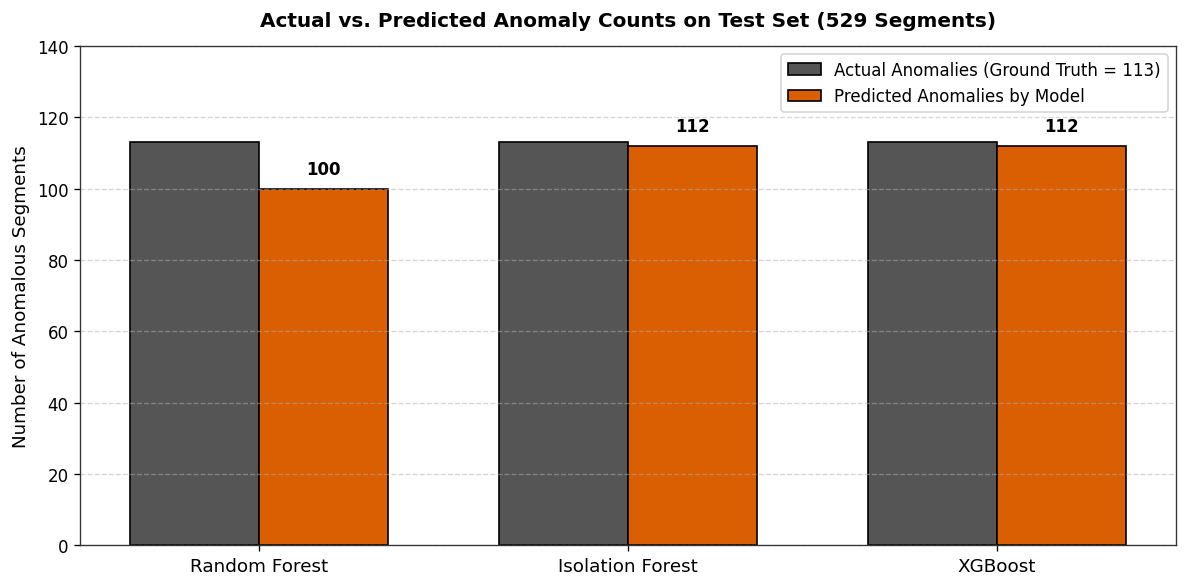

In [16]:
# 1. Actual vs Predicted Sample Counts
models_list = ["Random Forest", "Isolation Forest", "XGBoost"]
pred_cols = ["Random_Forest_Predicted", "Isolation_Forest_Predicted", "XGBoost_Predicted"]

fig, ax = plt.subplots(figsize=(10, 5), dpi=120)
x_idx = np.arange(len(models_list))
w = 0.35

actual_anom = int((df_predictions["Actual"] == 1).sum())
pred_anoms = [int((df_predictions[col] == 1).sum()) for col in pred_cols]

ax.bar(x_idx - w/2, [actual_anom]*3, w, label='Actual Anomalies (Ground Truth = 113)', color='#555555', edgecolor='black')
b_p = ax.bar(x_idx + w/2, pred_anoms, w, label='Predicted Anomalies by Model', color='#d95f02', edgecolor='black')

ax.set_title('Actual vs. Predicted Anomaly Counts on Test Set (529 Segments)', fontsize=12, fontweight='bold', pad=12)
ax.set_xticks(x_idx)
ax.set_xticklabels(models_list, fontsize=11)
ax.set_ylabel('Number of Anomalous Segments', fontsize=11)
ax.set_ylim(0, 140)
ax.grid(axis='y', linestyle='--', alpha=0.5)
ax.legend()

for b in b_p:
    h = b.get_height()
    ax.text(b.get_x() + b.get_width()/2., h + 3, f"{int(h)}", ha='center', va='bottom', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()

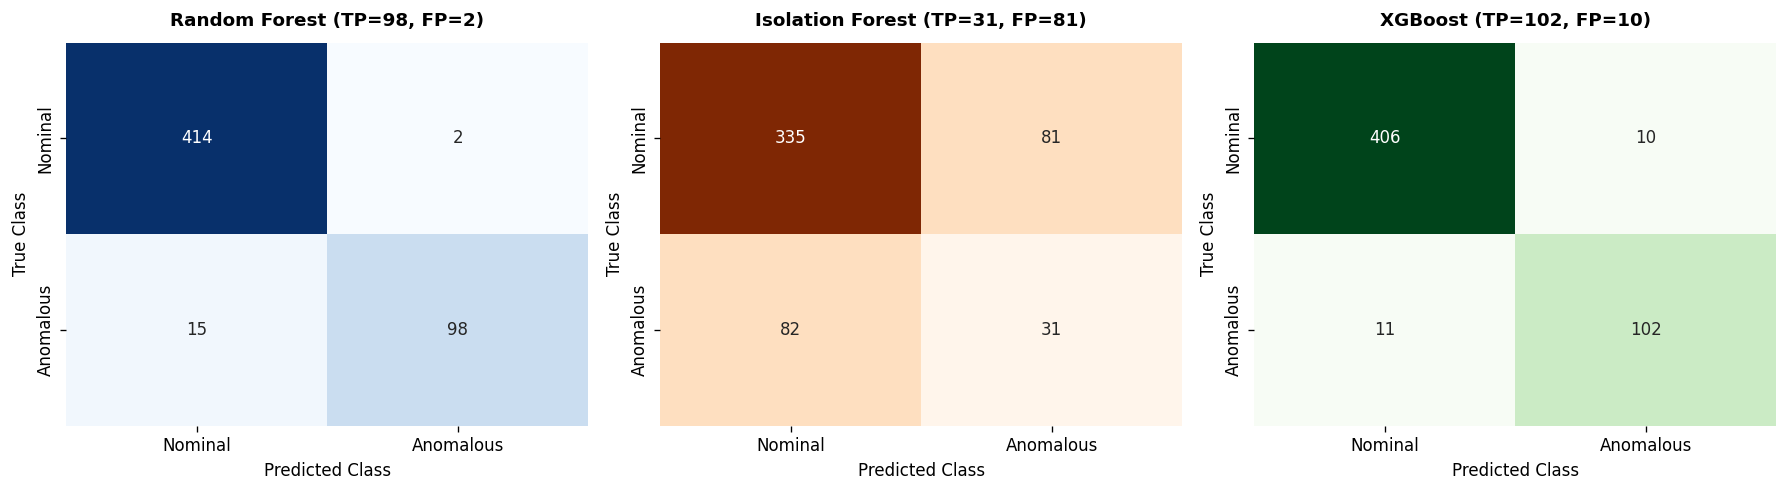

In [17]:
# 2. Side-by-Side Confusion Matrix Heatmaps
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), dpi=120)

cms = [cm_rf, cm_if, cm_xgb]
titles = [f"Random Forest (TP={tp_rf}, FP={fp_rf})",
          f"Isolation Forest (TP={tp_if}, FP={fp_if})",
          f"XGBoost (TP={tp_xgb}, FP={fp_xgb})"]
cmaps = ['Blues', 'Oranges', 'Greens']

for i in range(3):
    sns.heatmap(cms[i], annot=True, fmt='d', cmap=cmaps[i], cbar=False, ax=axes[i],
                xticklabels=['Nominal', 'Anomalous'], yticklabels=['Nominal', 'Anomalous'])
    axes[i].set_title(titles[i], fontsize=11, fontweight='bold', pad=10)
    axes[i].set_xlabel('Predicted Class', fontsize=10)
    axes[i].set_ylabel('True Class', fontsize=10)

plt.tight_layout()
plt.show()

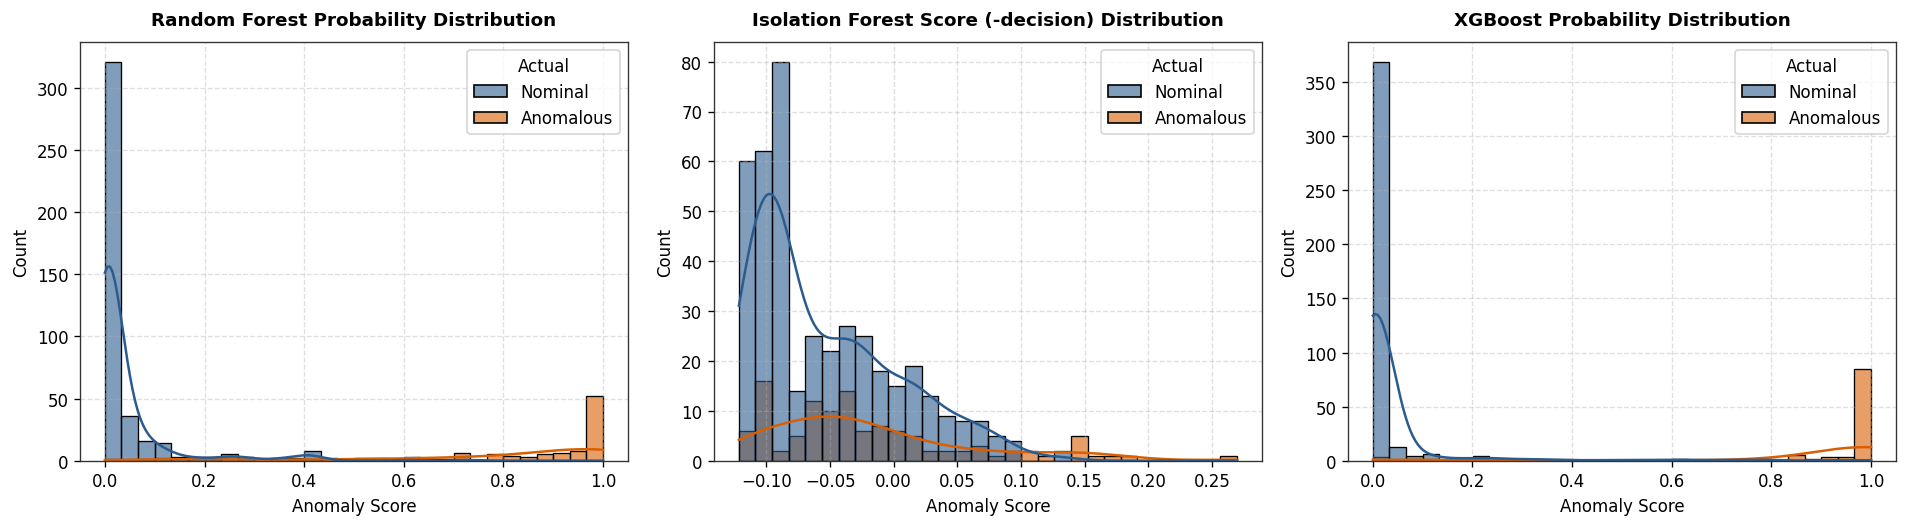

In [18]:
# 3. Anomaly Score Distributions by Actual Ground-Truth Class
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), dpi=120)

score_configs = [
    ("Random_Forest_Anomaly_Score", "Random Forest Probability", axes[0]),
    ("Isolation_Forest_Anomaly_Score", "Isolation Forest Score (-decision)", axes[1]),
    ("XGBoost_Anomaly_Score", "XGBoost Probability", axes[2])
]

for col, name, ax in score_configs:
    sns.histplot(data=df_predictions, x=col, hue=df_predictions["Actual"].map({0: "Nominal", 1: "Anomalous"}),
                 kde=True, bins=30, ax=ax, palette={"Nominal": "#2b5c8f", "Anomalous": "#d95f02"}, alpha=0.6)
    ax.set_title(f"{name} Distribution", fontsize=11, fontweight='bold', pad=10)
    ax.set_xlabel("Anomaly Score", fontsize=10)
    ax.grid(True, linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()

---
## Section 12: Final Conclusion & Interactive Dashboard Note

### 12.1 Experimental Summary
In this capstone implementation, we validated machine learning algorithms for spacecraft telemetry anomaly detection using authentic European Space Agency OPS-SAT CubeSat telemetry:
1. **Random Forest (Supervised Ensemble):** Emerged as the highest-precision model (**0.9800 Precision**, **0.9202 F1-score**, **0.9028 MCC**). It generated only **2 false positive alarms** across 416 nominal segments, proving optimal for minimizing ground operator alarm fatigue during steady-state orbital operations.
2. **XGBoost (Supervised Gradient Boosting):** Attained the highest detection sensitivity (**0.9027 Recall**), successfully catching **102 out of 113 anomalous segments**. This makes XGBoost the ideal choice during critical mission phases (such as launch and orbit deployment) where missed failures could jeopardize the spacecraft.
3. **Isolation Forest (Unsupervised Baseline):** Produced **0.6919 Accuracy** and **0.2768 Precision**, closely replicating published PyOD baselines and illustrating the operational reality of zero-label detection in orbit.

---

### 12.2 Important Note: The Interactive Streamlit Dashboard
This Jupyter Notebook focuses on reproducible algorithmic execution, metric benchmarking, and static diagnostic plotting. 

In addition to this notebook, a full-featured, multi-view **Interactive Web Dashboard** has been implemented in:
`dashboard/app.py`

* **Key Capabilities of the Dashboard:**
  * Real-time Key Performance Indicators (Total, Nominal, Anomalous, Test samples).
  * Interactive donut charts and grouped split visualizers.
  * Dropdown-driven model performance bar charts.
  * Interactive Confusion Matrix heatmaps.
  * Actual vs. Predicted categorization breakdown.
  * Dynamic continuous anomaly score histograms with marginal box plots.

> **Execution Note:** Because the Streamlit application is an interactive multi-threaded web server, it is executed as a standalone web app from the terminal via:
> ```bash
> streamlit run dashboard/app.py
> ```
> *(Or on Google Colab using localtunnel / ngrok bridges).*

---
**Demonstration completed successfully.**